<a href="https://colab.research.google.com/github/criwemasa/Inteligencia-Artificial/blob/main/Practica_01_Preprocesamiento_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 01 – Preprocesamiento de Datos
**Asignatura:** Inteligencia Artificial · **Carrera:** Computación · **Docente:** Rodrigo Tufiño

**Estudiante:** Wenceslao

Notebook con el código de cada actividad y las respuestas (P1–P23) en celdas Markdown.

## Celda de verificación

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt
print("✅ Todas las librerías cargadas correctamente")

✅ Todas las librerías cargadas correctamente


# FASE 1. Anatomía de un Dataset

In [2]:
import numpy as np
import pandas as pd

datos = {
    "nombre":        ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego"],
    "edad":          [21, 23, 20, 25, 22, 21],
    "promedio_gpa":  [8.9, 7.4, 9.5, 6.1, 8.2, 7.8],
    "horas_estudio": [18, 10, 22, 6, 15, 12],
    "distancia_km":  [2.5, 15.0, 0.8, 40.2, 5.1, 8.7],
    "carrera":       ["Computación","Computación","Redes","Redes","Computación","Redes"],
    "nivel_ingles":  ["Básico", "Intermedio","Avanzado","Básico","Avanzado","Intermedio"],
    "beca":          [1, 0, 1, 0, 1, 0],
    "aprobado":      ["Sí", "No", "Sí", "No", "Sí", "No"]
}

df = pd.DataFrame(datos)
print(df)
print(f"\nDimensiones del dataset: {df.shape}")

   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computación   
2   María    20           9.5             22           0.8        Redes   
3  Carlos    25           6.1              6          40.2        Redes   
4   Sofía    22           8.2             15           5.1  Computación   
5   Diego    21           7.8             12           8.7        Redes   

  nivel_ingles  beca aprobado  
0       Básico     1       Sí  
1   Intermedio     0       No  
2     Avanzado     1       Sí  
3       Básico     0       No  
4     Avanzado     1       Sí  
5   Intermedio     0       No  

Dimensiones del dataset: (6, 9)


## Actividad 1.1: Identifica la estructura

**P1. ¿Cuántas instancias tiene? ¿Qué representa cada una?**
El dataset tiene **6 instancias** (filas), `df.shape = (6, 9)`. Cada instancia representa **un estudiante real** (Ana, Luis, María, Carlos, Sofía y Diego), descrito por sus características académicas y personales.

**P2. Atributos, features y label**
- **Atributos (9 columnas):** `nombre`, `edad`, `promedio_gpa`, `horas_estudio`, `distancia_km`, `carrera`, `nivel_ingles`, `beca`, `aprobado`.
- **Features (para predecir si aprueba):** `edad`, `promedio_gpa`, `horas_estudio`, `distancia_km`, `carrera`, `nivel_ingles`, `beca`.
- **Label (variable objetivo):** `aprobado`.
- `nombre` es solo un identificador (ver P3).

**P3. ¿`nombre` debería ser feature?**
**No.** Es un identificador único: cada estudiante tiene un valor distinto, por lo que no contiene un patrón que se generalice a estudiantes nuevos. Si se incluyera, el modelo podría *memorizar* ("Ana → aprueba") en lugar de aprender relaciones reales, lo que causa sobreajuste (overfitting). Además, un nombre no tiene relación causal con aprobar y podría introducir sesgos.

## Actividad 1.2: Clasifica las variables

In [3]:
clasificacion = {
    "columna": ["edad", "promedio_gpa", "horas_estudio", "distancia_km",
                "carrera", "nivel_ingles", "beca", "aprobado"],
    "cuantitativa_o_cualitativa": ["Cuantitativa", "Cuantitativa", "Cuantitativa", "Cuantitativa",
                                   "Cualitativa", "Cualitativa", "Cualitativa", "Cualitativa"],
    "discreta_o_continua": ["Discreta", "Continua", "Continua", "Continua",
                            "NA", "NA", "NA", "NA"],
    "nominal_u_ordinal":   ["NA", "NA", "NA", "NA",
                            "Nominal", "Ordinal", "Nominal", "Nominal"]
}
df_tipos = pd.DataFrame(clasificacion)
print(df_tipos)

         columna cuantitativa_o_cualitativa discreta_o_continua  \
0           edad               Cuantitativa            Discreta   
1   promedio_gpa               Cuantitativa            Continua   
2  horas_estudio               Cuantitativa            Continua   
3   distancia_km               Cuantitativa            Continua   
4        carrera                Cualitativa                  NA   
5   nivel_ingles                Cualitativa                  NA   
6           beca                Cualitativa                  NA   
7       aprobado                Cualitativa                  NA   

  nominal_u_ordinal  
0                NA  
1                NA  
2                NA  
3                NA  
4           Nominal  
5           Ordinal  
6           Nominal  
7           Nominal  


**P4. `nivel_ingles`: ¿nominal u ordinal?**
Es **ordinal**. Sus categorías (Básico < Intermedio < Avanzado) tienen un **orden natural y significativo**, aunque la distancia entre niveles no sea medible exactamente. Sí importa al entrenar: si se trata como nominal (one-hot) se pierde la información de orden; si es ordinal se puede codificar como 0, 1, 2 (ordinal encoding) y conservar la jerarquía. Codificarla como nominal desperdicia información; codificar una nominal como número (ej. Computación=0, Redes=1) inventaría un orden que no existe.

**P5. `beca` (0/1): ¿cuantitativa discreta o cualitativa nominal?**
Es **cualitativa nominal (binaria)**. Los números 0 y 1 son solo *etiquetas* de "no tiene beca / tiene beca", no una cantidad. Calcular la media (0.5) no describe una "beca promedio" con sentido real; a lo sumo es la proporción de becados. Que esté guardada como número no la convierte en cuantitativa.

## Actividad 1.3: Inspeccionando tipos de datos

In [4]:
print("Tipos de datos detectados por pandas:")
print(df.dtypes)
print("\nEstadísticas descriptivas (solo numéricas):")
print(df.describe())

Tipos de datos detectados por pandas:
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado          object
dtype: object

Estadísticas descriptivas (solo numéricas):
            edad  promedio_gpa  horas_estudio  distancia_km      beca
count   6.000000      6.000000       6.000000       6.00000  6.000000
mean   22.000000      7.983333      13.833333      12.05000  0.500000
std     1.788854      1.192337       5.741661      14.68615  0.547723
min    20.000000      6.100000       6.000000       0.80000  0.000000
25%    21.000000      7.500000      10.500000       3.15000  0.000000
50%    21.500000      8.000000      13.500000       6.90000  0.500000
75%    22.750000      8.725000      17.250000      13.42500  1.000000
max    25.000000      9.500000      22.000000      40.20000  1.000000


**P6. ¿Coinciden los tipos de pandas con la clasificación teórica?**
Parcialmente. Pandas detecta `edad`, `horas_estudio` y `beca` como **int64**, `promedio_gpa` y `distancia_km` como **float64**, y `nombre`, `carrera`, `nivel_ingles`, `aprobado` como **object**.
Casos donde no coinciden:
- **`beca`** es `int64` (numérico), pero conceptualmente es **cualitativa nominal**. Pandas solo mira cómo se almacena el dato, no su significado.
- **`horas_estudio`** es `int64` porque aquí se registraron horas enteras, pero conceptualmente es **continua** (se podrían estudiar 12.5 h).
- **`nivel_ingles`** es `object`, igual que una nominal; pandas no sabe que es **ordinal**.

Pandas infiere el *tipo de almacenamiento*, no el *tipo estadístico* de la variable.

In [5]:
# Verificación de P7: desviación estándar por columna
print(df.describe().loc["std"].round(3))
print("\nColumna con mayor std:", df.describe().loc["std"].idxmax())

edad              1.789
promedio_gpa      1.192
horas_estudio     5.742
distancia_km     14.686
beca              0.548
Name: std, dtype: float64

Columna con mayor std: distancia_km


**P7. ¿Qué columna tiene mayor dispersión? ¿Qué problema genera en KNN?**
`distancia_km` tiene la mayor desviación estándar (≈ **14.69**), frente a ≈1.19 de `promedio_gpa`, ≈5.74 de `horas_estudio` y ≈1.79 de `edad`.
KNN se basa en **distancias** (euclidiana). Con escalas tan distintas, la diferencia en kilómetros (decenas) **domina** el cálculo y las demás variables (como el GPA, con diferencias de 1–3 puntos) casi no influyen. El modelo estaría "mirando" solo la distancia, aunque no sea la variable más importante.

# FASE 2. Escalado con NumPy

## Actividad 2.1: Preparando los datos

In [6]:
columnas_numericas = ["promedio_gpa", "horas_estudio", "distancia_km"]
X = df[columnas_numericas].values.astype(float)

print("Matriz de datos original:")
print(X)
print(f"\nForma: {X.shape} → {X.shape[0]} instancias, {X.shape[1]} features")

Matriz de datos original:
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma: (6, 3) → 6 instancias, 3 features


**P8. ¿Por qué excluimos `edad` y `beca`? ¿Tiene sentido escalar `beca`?**
En esta fase solo se usan variables **numéricas continuas**. `edad` es discreta y tiene un rango muy estrecho (20–25), y `beca` es una variable **categórica binaria** disfrazada de número.
**No tiene sentido escalar `beca`**: ya está en {0, 1}, que coincide con el rango de Min-Max, y estandarizarla produciría valores como −0.99 y 1.01 sin interpretación útil. Las categóricas se codifican, no se escalan.

## Actividad 2.2: Normalización Min-Max

In [7]:
def min_max_manual(X):
    """
    Normalización Min-Max: transforma cada columna al rango [0, 1]
    Fórmula: x' = (x - min) / (max - min)
    """
    X_min = X.min(axis=0)   # mínimo por columna
    X_max = X.max(axis=0)   # máximo por columna
    X_norm = (X - X_min) / (X_max - X_min)
    return X_norm, X_min, X_max

X_minmax, mins, maxs = min_max_manual(X)

print("=== RESULTADO MIN-MAX ===")
print(f"{'Feature':<18} {'Min original':>14} {'Max original':>14}")
print("-" * 48)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {mins[i]:>14.2f} {maxs[i]:>14.2f}")

print("\nDatos normalizados (Min-Max):")
df_minmax = pd.DataFrame(X_minmax, columns=[c+"_mm" for c in columnas_numericas])
print(df_minmax.round(4))

=== RESULTADO MIN-MAX ===
Feature              Min original   Max original
------------------------------------------------
promedio_gpa                 6.10           9.50
horas_estudio                6.00          22.00
distancia_km                 0.80          40.20

Datos normalizados (Min-Max):
   promedio_gpa_mm  horas_estudio_mm  distancia_km_mm
0           0.8235            0.7500           0.0431
1           0.3824            0.2500           0.3604
2           1.0000            1.0000           0.0000
3           0.0000            0.0000           1.0000
4           0.6176            0.5625           0.1091
5           0.5000            0.3750           0.2005


In [8]:
# Verificación P9
print("Mínimo por columna:", X_minmax.min(axis=0))
print("Máximo por columna:", X_minmax.max(axis=0))

Mínimo por columna: [0. 0. 0.]
Máximo por columna: [1. 1. 1.]


**P9. Rango tras Min-Max**
Cualquier columna queda en **[0, 1]**; la verificación lo confirma (mínimo 0.0 y máximo 1.0 en las tres columnas).
- **0.0** = el valor es el **mínimo** observado de esa columna (ej. María con 0.8 km).
- **1.0** = el valor es el **máximo** observado (ej. Carlos con 40.2 km).
Los valores intermedios indican la posición proporcional entre ambos extremos.

**P10. Efecto de un nuevo estudiante a 80 km**
El máximo pasaría de 40.2 a 80, así que **todos los valores transformados cambian** y se comprimen hacia 0. Por ejemplo, Carlos pasaría de 1.00 a ≈0.50 y Ana de 0.043 a ≈0.021. **Sí es un problema**: Min-Max depende totalmente de los extremos, por lo que un solo outlier distorsiona la escala del resto, reduce la resolución entre los datos "normales" y hace que los parámetros dejen de ser estables.

In [9]:
# Comprobación numérica de P10
X80 = np.vstack([X, [8.0, 14, 80.0]])
mm80, _, _ = min_max_manual(X80)
print("distancia_km Min-Max SIN el estudiante de 80 km:", X_minmax[:, 2].round(4))
print("distancia_km Min-Max CON el estudiante de 80 km:", mm80[:6, 2].round(4))

distancia_km Min-Max SIN el estudiante de 80 km: [0.0431 0.3604 0.     1.     0.1091 0.2005]
distancia_km Min-Max CON el estudiante de 80 km: [0.0215 0.1793 0.     0.4975 0.0543 0.0997]


## Actividad 2.3: Estandarización Z-Score

In [10]:
def zscore_manual(X):
    """
    Z-Score: transforma cada columna a media=0 y desv.est.=1
    Fórmula: z = (x - media) / desviacion_estandar
    """
    media = X.mean(axis=0)
    std  = X.std(axis=0)       # desviación estándar de la población
    X_z  = (X - media) / std
    return X_z, media, std

X_zscore, medias, stds = zscore_manual(X)

print("=== RESULTADO Z-SCORE ===")
print(f"{'Feature':<18} {'Media':>10} {'Desv.Est.':>12}")
print("-" * 42)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {medias[i]:>10.3f} {stds[i]:>12.3f}")

print("\nDatos estandarizados (Z-Score):")
df_z = pd.DataFrame(X_zscore, columns=[c+"_z" for c in columnas_numericas])
print(df_z.round(4))

=== RESULTADO Z-SCORE ===
Feature                 Media    Desv.Est.
------------------------------------------
promedio_gpa            7.983        1.088
horas_estudio          13.833        5.241
distancia_km           12.050       13.407

Datos estandarizados (Z-Score):
   promedio_gpa_z  horas_estudio_z  distancia_km_z
0          0.8422           0.7950         -0.7123
1         -0.5359          -0.7314          0.2200
2          1.3934           1.5581         -0.8391
3         -1.7303          -1.4945          2.0997
4          0.1991           0.2226         -0.5184
5         -0.1684          -0.3498         -0.2499


In [11]:
# Verificación (en la guía esta pregunta aparece repetida como "P9"; corresponde a P11)
print("Media por columna:", X_zscore.mean(axis=0).round(10))
print("Std por columna:  ", X_zscore.std(axis=0).round(10))
print("Mín:", X_zscore.min(axis=0).round(3), " Máx:", X_zscore.max(axis=0).round(3))

Media por columna: [ 0. -0.  0.]
Std por columna:   [1. 1. 1.]
Mín: [-1.73  -1.495 -0.839]  Máx: [1.393 1.558 2.1  ]


**P11 (en la guía aparece repetida como "P9"). Rango tras Z-Score**
Z-Score **no tiene un rango fijo**: lo que se garantiza es **media = 0 y desviación estándar = 1**. Los valores pueden ser negativos o positivos y, en la práctica, la mayoría cae entre −3 y 3. Un valor **0.0** significa que el dato es igual a la media; un **1.0** significa que está una desviación estándar por encima de la media. (Observa que Min-Max sí tiene rango [0,1], pero Z-Score no.)

**P12. Carlos, `horas_estudio` = 6**
Su z-score es ≈ **−1.49**: estudia **1.49 desviaciones estándar por debajo de la media** del grupo (13.83 h). **No significa que estudie "mal"**; el signo solo indica posición relativa (por debajo del promedio). Es el estudiante que menos horas estudia del grupo, pero eso no es un juicio de calidad.

**P13. Carlos vs Sofía en `distancia_km`**
- Min-Max: Carlos = **1.0000**, Sofía = **0.1091**.
- Z-Score: Carlos = **2.0997**, Sofía = **−0.5184**.

**Z-Score es más informativo sobre la "rareza"**: un z de 2.1 dice que Carlos está a más de 2 desviaciones estándar de la media, lo cual es inusual. Min-Max solo dice que es el máximo, sin decir *cuánto* se aleja del grupo ni si es raro. Además, Z-Score separa por signo quién está por encima o por debajo del promedio.

## Actividad 2.4: Comparación visual

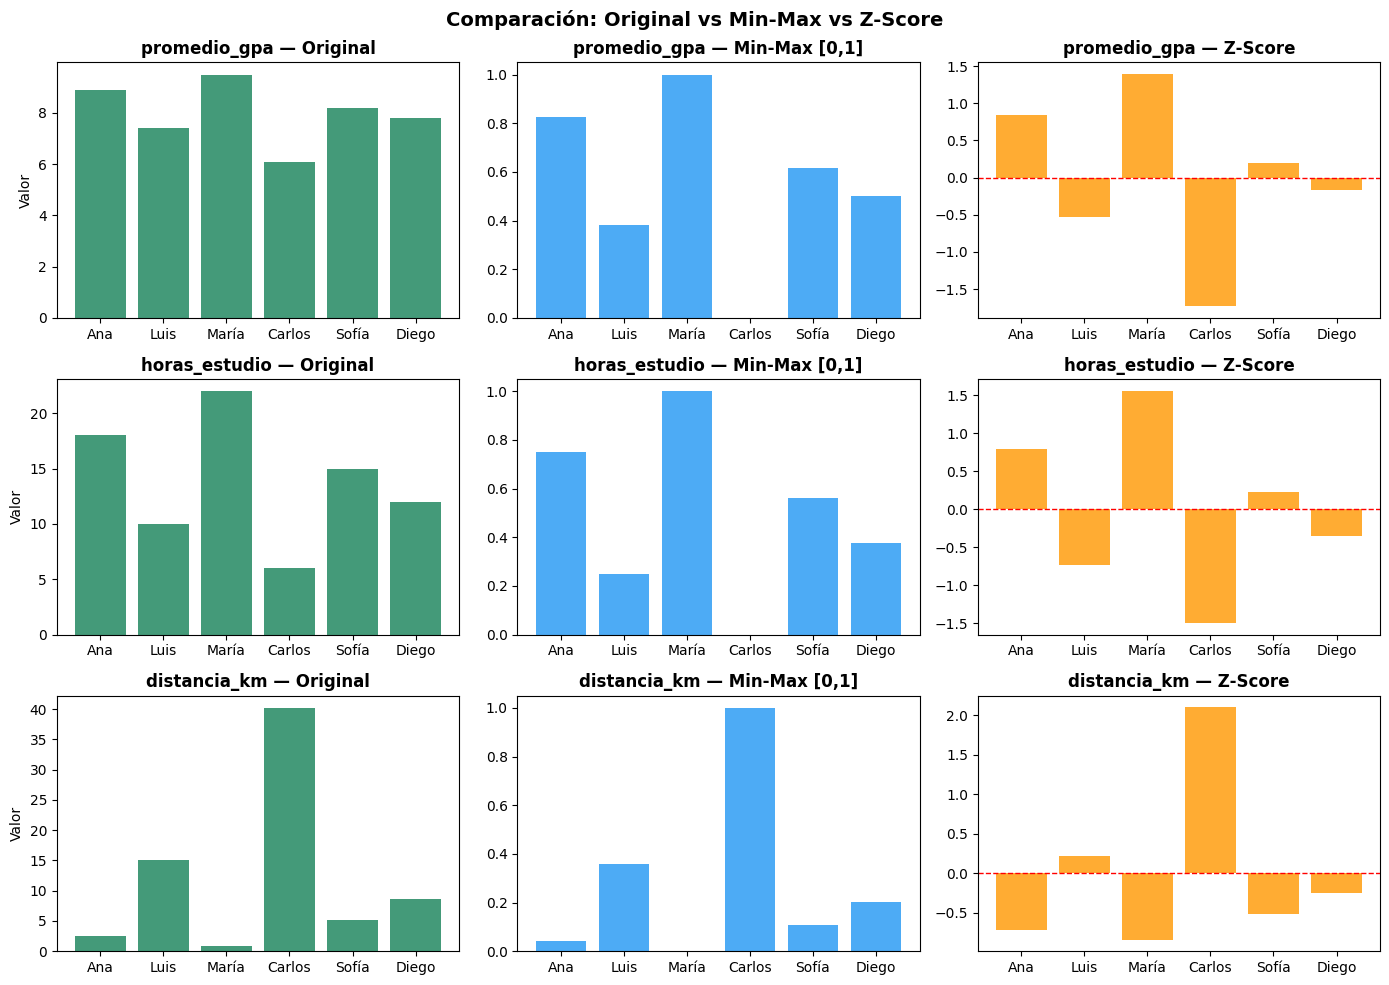

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
nombres = df["nombre"].values

for i, col in enumerate(columnas_numericas):
    # Original
    axes[i, 0].bar(nombres, X[:, i], color="#158158", alpha=0.8)
    axes[i, 0].set_title(f"{col} — Original", fontweight='bold')
    axes[i, 0].set_ylabel("Valor")

    # Min-Max
    axes[i, 1].bar(nombres, X_minmax[:, i], color="#2196F3", alpha=0.8)
    axes[i, 1].set_title(f"{col} — Min-Max [0,1]", fontweight='bold')

    # Z-Score
    axes[i, 2].bar(nombres, X_zscore[:, i], color="#FF9800", alpha=0.8)
    axes[i, 2].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[i, 2].set_title(f"{col} — Z-Score", fontweight='bold')

plt.suptitle("Comparación: Original vs Min-Max vs Z-Score", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("comparacion_escalado.png", dpi=100)
plt.show()

**P14. ¿Se mantienen las proporciones? ¿Qué cambia?**
Sí, **la forma del gráfico (las proporciones relativas entre estudiantes) es idéntica** en las tres versiones: Carlos sigue siendo el más lejano y María la más cercana. Lo que cambia es **solo la escala y el origen de los ejes**: Original (km), Min-Max (comprime a [0,1]) y Z-Score (centra en 0 y mide en desviaciones estándar). Ambas transformaciones son lineales (afines), por eso no alteran el orden ni la forma relativa.

## Actividad 2.5: Simulando un outlier extremo

In [13]:
# Añadimos un estudiante con una distancia extrema
X_con_outlier = np.vstack([X, [8.5, 14, 120.0]])   # 120 km

X_mm_con_outlier, _, _ = min_max_manual(X_con_outlier)
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)

print("=== Columna distancia_km con outlier (120 km) ===")
print(f"\n{'Estudiante':<10} {'Original':>10} {'Min-Max':>10} {'Z-Score':>10}")
print("-" * 44)
nombres_ext = list(nombres) + ["Nuevo"]
for j in range(len(nombres_ext)):
    print(f"{nombres_ext[j]:<10} {X_con_outlier[j,2]:>10.1f} "
          f"{X_mm_con_outlier[j,2]:>10.4f} {X_z_con_outlier[j,2]:>10.4f}")

=== Columna distancia_km con outlier (120 km) ===

Estudiante   Original    Min-Max    Z-Score
--------------------------------------------
Ana               2.5     0.0143    -0.6280
Luis             15.0     0.1191    -0.3137
María             0.8     0.0000    -0.6708
Carlos           40.2     0.3305     0.3201
Sofía             5.1     0.0361    -0.5626
Diego             8.7     0.0663    -0.4721
Nuevo           120.0     1.0000     2.3271


In [14]:
# Extra: comparación con RobustScaler sobre los mismos datos (para P15)
rb_demo = RobustScaler().fit_transform(X_con_outlier[:, [2]])
print("Robust Scaler (distancia_km con outlier):")
for n, v in zip(nombres_ext, rb_demo[:, 0]):
    print(f"{n:<10} {v:>8.4f}")

Robust Scaler (distancia_km con outlier):
Ana         -0.2605
Luis         0.2647
María       -0.3319
Carlos       1.3235
Sofía       -0.1513
Diego        0.0000
Nuevo        4.6765


**P15. Efecto del outlier de 120 km**
En Min-Max, los 6 estudiantes originales quedan comprimidos en el rango ≈ **[0, 0.33]** (Carlos pasa de 1.0 a 0.33; Ana ≈ 0.014, Sofía ≈ 0.036), mientras que el nuevo ocupa el 1.0. **El problema:** se pierde la capacidad de distinguir entre los estudiantes "normales" y la escala queda dominada por un solo dato extremo.

**¿Por qué Z-Score es más robusto?** Z-Score **no fuerza los datos a un rango fijo**, de modo que el outlier simplemente obtiene un z alto (≈ 2.33) y no "aplasta" necesariamente la escala de los demás; los datos normales siguen con valores del orden de −0.7 a 0.3, y además interpreta el valor en desviaciones estándar. *Aclaración honesta:* Z-Score tampoco es inmune, porque la media y la std se calculan con el outlier incluido (se inflan) y los demás z-scores también se desplazan y se encogen.

**¿Existe una técnica mejor?** Sí, el **Robust Scaler**: usa la **mediana y el rango intercuartílico (IQR)**, estadísticos que casi no se ven afectados por valores extremos. Los datos "normales" conservan su escala y el outlier queda como un valor grande y claramente identificable (ver celda anterior).

# FASE 3. Dataset real con Pandas: Palmer Penguins

In [15]:
import pandas as pd

# Cargamos el dataset directamente desde Hugging Face
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)

print("=== PRIMERA VISTA DEL DATASET ===")
print(df_penguins.head(8))
print(f"\nDimensiones: {df_penguins.shape}")
print(f"\nColumnas: {list(df_penguins.columns)}")

=== PRIMERA VISTA DEL DATASET ===
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   
6  Adelie  Torgersen            38.9           17.8              181.0   
7  Adelie  Torgersen            39.2           19.6              195.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  
5       3650.0    male  2007  
6       3625.0  female  2007  
7       4675.0    male  2007  

Dimensiones: (344, 

## Actividad 3.1: Exploración inicial obligatoria

In [16]:
print("\n=== TIPOS DE DATOS ===")
print(df_penguins.dtypes)

print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())

print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_penguins.describe())

print("\n=== VALORES ÚNICOS EN COLUMNAS CATEGÓRICAS ===")
for col in df_penguins.select_dtypes(include='object').columns:
    print(f"{col}: {df_penguins[col].unique()}")


=== TIPOS DE DATOS ===
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

=== VALORES NULOS ===
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

=== ESTADÍSTICAS DESCRIPTIVAS ===
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  \
count      342.000000     342.000000         342.000000   342.000000   
mean        43.921930      17.151170         200.915205  4201.754386   
std          5.459584       1.974793          14.061714   801.954536   
min         32.100000      13.100000         172.000000  2700.000000   
25%         39.225000      15.600000         190.000000  3550.000000   
50%         44.450000      17.30000

**P16. Instancias, features y label**
- **Instancias:** **344** pingüinos (cada fila es un pingüino observado).
- **Features numéricas:** `bill_length_mm` (largo del pico), `bill_depth_mm` (profundidad del pico), `flipper_length_mm` (largo de la aleta) y `body_mass_g` (masa corporal). Si el CSV incluye `year`, es una variable temporal (discreta) que normalmente no se usa como feature predictiva.
- **Label más lógico:** `species` (Adelie, Chinstrap, Gentoo), para una tarea de clasificación multiclase.

**P17. Valores nulos**
Sí. En el Palmer Penguins estándar hay nulos en `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm` y `body_mass_g` (2 cada una) y en `sex` (alrededor de 11); verifica los conteos exactos en la salida de `isnull().sum()`. Al eliminar las filas con nulos quedan **333 filas**.
Es importante tratarlos **antes** de escalar porque: (1) `NaN` se propaga en operaciones de NumPy (`mean`, `min`, `max` devuelven `NaN`, así que todo el cálculo falla); (2) aunque sklearn los ignora al hacer `fit`, los deja como `NaN` tras `transform` y los modelos como KNN o regresión no los aceptan; (3) imputar o eliminar después del escalado distorsiona las estadísticas.

## Actividad 3.2: Clasificación de variables del dataset

**P18. Clasificación completa de `df_penguins`**

| Columna | Cuantitativa / Cualitativa | Discreta / Continua | Nominal / Ordinal |
|---|---|---|---|
| species | Cualitativa | NA | Nominal |
| island | Cualitativa | NA | Nominal |
| bill_length_mm | Cuantitativa | Continua | NA |
| bill_depth_mm | Cuantitativa | Continua | NA |
| flipper_length_mm | Cuantitativa | Continua (medida en mm enteros) | NA |
| body_mass_g | Cuantitativa | Continua (medida en g enteros) | NA |
| sex | Cualitativa | NA | Nominal (binaria) |
| year (si existe) | Cuantitativa | Discreta | NA |

`sex` e `island` son **ambas nominales**: sus categorías no tienen un orden inherente. Si ordenáramos las islas por temperatura promedio del océano, **la variable sigue siendo nominal por naturaleza**; lo que haríamos es crear una **nueva variable** (la temperatura) que sí es cuantitativa, o imponer un orden artificial que solo sería ordinal si ese criterio tuviera relevancia para el problema. Lo correcto sería usar la temperatura como feature numérica, no reinterpretar `island`.

## Actividad 3.3: Preprocesamiento y escalado

In [17]:
# Paso 1: Eliminar filas con valores nulos
df_clean = df_penguins.dropna()
print(f"Filas originales: {len(df_penguins)} → Filas limpias: {len(df_clean)}")

# Paso 2: Seleccionar features numéricas
features_num = ["bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g"]
X_penguins = df_clean[features_num].values

print("\nEstadísticas ANTES del escalado:")
print(pd.DataFrame(X_penguins, columns=features_num).describe().round(2))

Filas originales: 344 → Filas limpias: 333

Estadísticas ANTES del escalado:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


**P19. `body_mass_g` vs `bill_depth_mm`**
Sin escalar, **`body_mass_g` tendría muchísimo más peso** en el cálculo de distancia: sus diferencias son de cientos de gramos, mientras que las de `bill_depth_mm` son de pocos milímetros, así que la masa corporal domina la distancia euclidiana. **No es justo biológicamente**: la profundidad del pico podría ser tan o más discriminante entre especies que la masa, pero su contribución quedaría anulada solo por la unidad de medida.

## Actividad 3.4: Análisis de distribuciones

In [18]:
# Paso 3: Aplicar Min-Max
mm = MinMaxScaler()
X_mm = mm.fit_transform(X_penguins)

# Paso 4: Aplicar Z-Score
zs = StandardScaler()
X_zs = zs.fit_transform(X_penguins)

# Paso 5: Comparar estadísticas
print("\n--- Min-Max ---")
print(pd.DataFrame(X_mm, columns=features_num).describe().round(4))

print("\n--- Z-Score ---")
print(pd.DataFrame(X_zs, columns=features_num).describe().round(4))


--- Min-Max ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean           0.4325         0.4839             0.4910       0.4186
std            0.1989         0.2344             0.2376       0.2237
min            0.0000         0.0000             0.0000       0.0000
25%            0.2691         0.2976             0.3051       0.2361
50%            0.4509         0.5000             0.4237       0.3750
75%            0.6000         0.6667             0.6949       0.5764
max            1.0000         1.0000             1.0000       1.0000

--- Z-Score ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean          -0.0000        -0.0000             0.0000      -0.0000
std            1.0015         1.0015             1.0015       1.0015
min           -2.1780        -2.0673            -2.0699      -1.8744


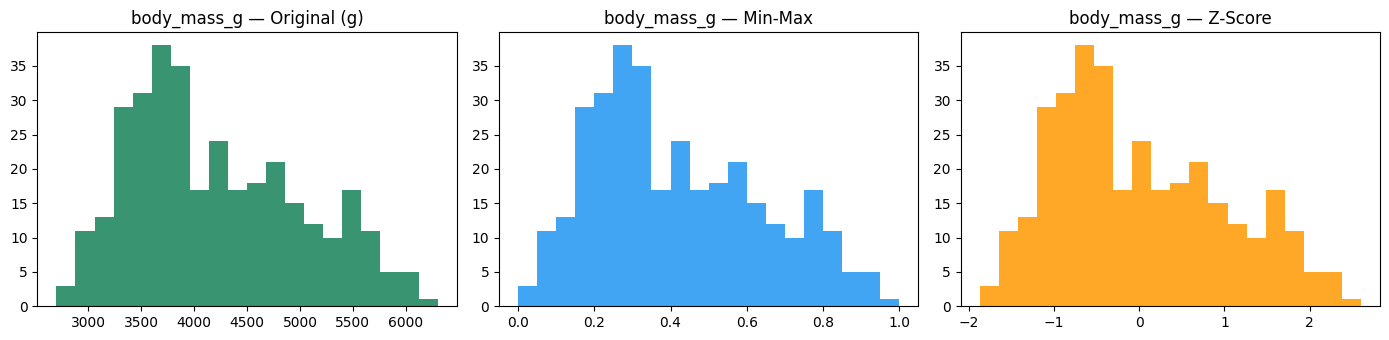

Asimetría (skewness) de body_mass_g: 0.47


In [19]:
# Histogramas de body_mass_g: original vs Min-Max vs Z-Score (apoyo para P20 y P21)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
j = features_num.index("body_mass_g")
for a, data, t, c in zip(ax, [X_penguins[:, j], X_mm[:, j], X_zs[:, j]],
                         ["Original (g)", "Min-Max", "Z-Score"],
                         ["#158158", "#2196F3", "#FF9800"]):
    a.hist(data, bins=20, color=c, alpha=0.85)
    a.set_title(f"body_mass_g — {t}")
plt.tight_layout(); plt.show()

from scipy.stats import skew
print("Asimetría (skewness) de body_mass_g:", round(skew(X_penguins[:, j]), 3))

**P20. ¿El escalado cambia la forma de la distribución?**
**No, solo cambia la escala (y la ubicación) de los ejes.** Los histogramas son idénticos en forma; solo cambian los valores del eje horizontal. Esto importa al evaluar normalidad: **estandarizar no vuelve normal a un dato que no lo es**. Z-Score centra y reescala, pero una distribución sesgada seguirá sesgada. Para cambiar la forma se requieren transformaciones no lineales (log, Box-Cox, etc.).

**P21. Distribución de `body_mass_g`**
No es una campana de Gauss perfecta: presenta una **ligera asimetría positiva (cola a la derecha)** y tiende a verse multimodal, porque mezcla tres especies (Gentoo son notablemente más pesados) y dos sexos. Revisa la asimetría calculada en la celda anterior para respaldarlo con el número obtenido.
**Sobre la elección:** Z-Score es más natural cuando los datos son aproximadamente simétricos/normales; Min-Max funciona con cualquier forma pero es sensible a outliers. Con asimetría marcada u outliers, la mejor opción sería **RobustScaler** o una transformación logarítmica previa. Con el sesgo leve de este dataset, tanto Min-Max como Z-Score son aceptables.

# FASE 4. Hugging Face + sklearn

## Actividad 4.1: Retornando al dataset limpio

In [20]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)
df_clean = df_penguins.dropna()

features_num = ["bill_length_mm", "bill_depth_mm",
                "flipper_length_mm", "body_mass_g"]

X = df_clean[features_num].values

print(f"Dataset listo: {X.shape[0]} instancias, {X.shape[1]} features")
print(f"\nEstadísticas originales:")
print(pd.DataFrame(X, columns=features_num).describe().round(2))

Dataset listo: 333 instancias, 4 features

Estadísticas originales:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


In [21]:
# P22 (primera): rango de cada feature
rangos = X.max(axis=0) - X.min(axis=0)
for f, r in zip(features_num, rangos):
    print(f"{f:<20} rango = {r:.2f}")
print("\nMayor rango:", features_num[rangos.argmax()], "→", round(rangos.max(), 2))
print("Menor rango:", features_num[rangos.argmin()], "→", round(rangos.min(), 2))

bill_length_mm       rango = 27.50
bill_depth_mm        rango = 8.40
flipper_length_mm    rango = 59.00
body_mass_g          rango = 3600.00

Mayor rango: body_mass_g → 3600.0
Menor rango: bill_depth_mm → 8.4


**P22 (primera). Mayor y menor rango**
La feature de **mayor rango es `body_mass_g`** (del orden de ~3000 g, de ≈2700 a ≈6300) y la de **menor rango es `bill_depth_mm`** (≈8 mm, de ≈13 a ≈21). Los valores exactos salen de la celda anterior. La enorme diferencia (cientos de veces) confirma la necesidad de escalar. *(Nota: la guía numera dos veces P22 y P23; aquí se distinguen como "primera" y "segunda".)*

## Actividad 4.2: División train/test

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(
    X,
    test_size=0.2,     # 80% entrenamiento, 20% prueba
    random_state=42    # fija la aleatoriedad para reproducibilidad
)

print(f"Train: {X_train.shape} → {X_train.shape[0]} pingüinos")
print(f"Test:  {X_test.shape}  → {X_test.shape[0]} pingüinos")

Train: (266, 4) → 266 pingüinos
Test:  (67, 4)  → 67 pingüinos


**P23 (primera). ¿Por qué dividir antes de escalar? (data leakage)**
Si escalamos primero con **todo** el dataset, el scaler calcula sus parámetros (mínimo/máximo, media/std, mediana/IQR) usando también los datos del test. Así, **información del test "se filtra"** al proceso de entrenamiento: los valores de entrenamiento quedan transformados con estadísticas que incluyen datos que el modelo *nunca debería haber visto*. Esto se llama **data leakage** (fuga de datos) y hace que la evaluación sea demasiado optimista, porque el test deja de ser realmente "nuevo". Lo correcto: el scaler **aprende solo del train** (`fit_transform`) y luego aplica esos mismos parámetros al test (`transform`), igual que ocurriría con datos nuevos en producción.

## Actividad 4.3: Aplicando los tres escaladores

In [23]:
# Instanciar los tres escaladores
mm_scaler = MinMaxScaler()
zs_scaler = StandardScaler()
rb_scaler = RobustScaler()

# Aplicar a train: fit + transform
X_train_mm = mm_scaler.fit_transform(X_train)
X_train_zs = zs_scaler.fit_transform(X_train)
X_train_rb = rb_scaler.fit_transform(X_train)

# Aplicar a test: solo transform (NO fit)
X_test_mm = mm_scaler.transform(X_test)
X_test_zs = zs_scaler.transform(X_test)
X_test_rb = rb_scaler.transform(X_test)

print("Parámetros aprendidos por MinMaxScaler (sobre train):")
print(f"  Mínimos: {mm_scaler.data_min_.round(2)}")
print(f"  Máximos: {mm_scaler.data_max_.round(2)}")

print("\nParámetros aprendidos por StandardScaler (sobre train):")
print(f"  Medias:  {zs_scaler.mean_.round(2)}")
print(f"  Std:     {zs_scaler.scale_.round(2)}")

print("\nParámetros aprendidos por RobustScaler (sobre train):")
print(f"  Medianas: {rb_scaler.center_.round(2)}")
print(f"  IQR:      {rb_scaler.scale_.round(2)}")

Parámetros aprendidos por MinMaxScaler (sobre train):
  Mínimos: [  32.1   13.1  172.  2700. ]
  Máximos: [  59.6   21.5  231.  6050. ]

Parámetros aprendidos por StandardScaler (sobre train):
  Medias:  [  44.08   17.07  201.41 4232.61]
  Std:     [  5.41   1.97  14.24 809.57]

Parámetros aprendidos por RobustScaler (sobre train):
  Medianas: [  44.9   17.2  197.  4100. ]
  IQR:      [   8.9    3.2   24.  1200. ]


In [24]:
# P22 (segunda): comparar con los cálculos manuales de NumPy
def min_max_manual(X):
    X_min = X.min(axis=0); X_max = X.max(axis=0)
    return (X - X_min) / (X_max - X_min), X_min, X_max

_, mins_train, maxs_train = min_max_manual(X_train)   # manual sobre TRAIN
_, mins_all,   maxs_all   = min_max_manual(X)         # manual sobre TODO el dataset

print("sklearn  min:", mm_scaler.data_min_.round(2), " max:", mm_scaler.data_max_.round(2))
print("manual (train) min:", mins_train.round(2), " max:", maxs_train.round(2))
print("manual (todo)  min:", mins_all.round(2),   " max:", maxs_all.round(2))
print("\n¿sklearn == manual sobre train?", np.allclose(mm_scaler.data_min_, mins_train) and np.allclose(mm_scaler.data_max_, maxs_train))
print("¿sklearn == manual sobre todo?  ", np.allclose(mm_scaler.data_min_, mins_all) and np.allclose(mm_scaler.data_max_, maxs_all))

# Valores del test fuera de [0,1] por no haber participado en el fit
print("\nMín/Máx del test escalado con Min-Max:", X_test_mm.min(axis=0).round(3), X_test_mm.max(axis=0).round(3))

sklearn  min: [  32.1   13.1  172.  2700. ]  max: [  59.6   21.5  231.  6050. ]
manual (train) min: [  32.1   13.1  172.  2700. ]  max: [  59.6   21.5  231.  6050. ]
manual (todo)  min: [  32.1   13.1  172.  2700. ]  max: [  59.6   21.5  231.  6300. ]

¿sklearn == manual sobre train? True
¿sklearn == manual sobre todo?   False

Mín/Máx del test escalado con Min-Max: [0.091 0.012 0.102 0.06 ] [0.804 0.952 0.983 1.075]


**P22 (segunda). Parámetros de MinMaxScaler vs cálculo manual**
- Si el cálculo manual se hace **sobre el mismo `X_train`**, los mínimos y máximos son **exactamente iguales** a `data_min_` y `data_max_` (la fórmula es la misma).
- Si se compara con los de **todo el dataset** (o con los de la Fase 2, que usó otro dataset de estudiantes), **puede haber diferencias pequeñas**: el train solo contiene el 80 % de los datos, y los extremos del dataset completo pueden haber caído en el test. Esa diferencia es justamente el efecto del `fit` solo sobre train.
- Consecuencia: en el test pueden aparecer valores **ligeramente fuera de [0, 1]** si el test contiene valores más extremos que el train.

In [25]:
# P23 (segunda): mediana e IQR manuales de body_mass_g (columna 3) en el train
col = X_train[:, 3]
mediana = np.median(col)
q1, q3 = np.percentile(col, [25, 75])
iqr = q3 - q1

print(f"Manual  → mediana: {mediana:.4f}, IQR: {iqr:.4f}")
print(f"sklearn → center_[3]: {rb_scaler.center_[3]:.4f}, scale_[3]: {rb_scaler.scale_[3]:.4f}")
print("¿Coinciden?", np.isclose(mediana, rb_scaler.center_[3]) and np.isclose(iqr, rb_scaler.scale_[3]))

Manual  → mediana: 4100.0000, IQR: 1200.0000
sklearn → center_[3]: 4100.0000, scale_[3]: 1200.0000
¿Coinciden? True


**P23 (segunda). Mediana e IQR de `body_mass_g`**
La mediana (`np.median`) y el IQR (`Q3 − Q1` con `np.percentile(col, [25, 75])`) calculados con NumPy **coinciden con `rb_scaler.center_[3]` y `rb_scaler.scale_[3]`**, porque RobustScaler usa por defecto el rango intercuartílico (percentiles 25–75) con la misma interpolación lineal que NumPy. La celda anterior imprime `True`.

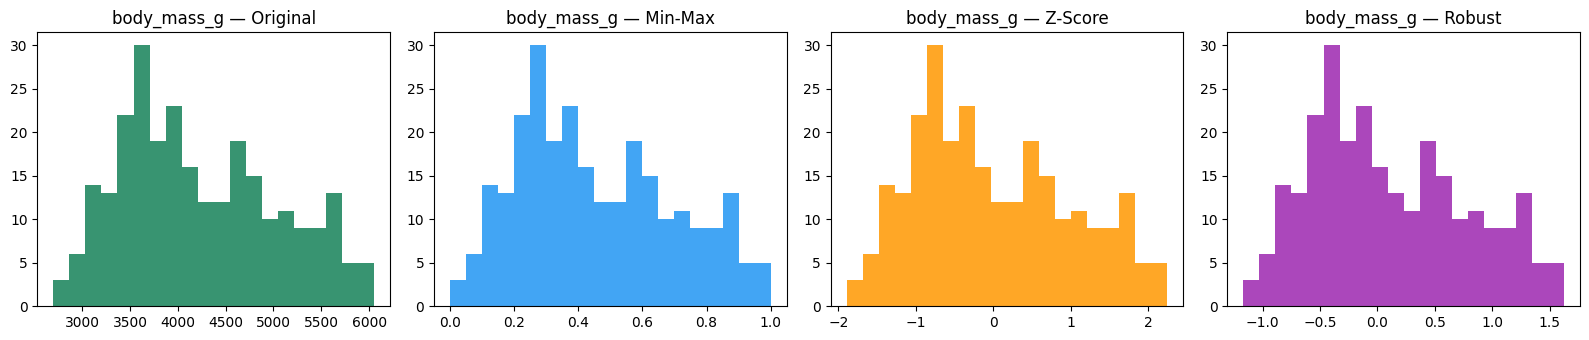

In [26]:
# Comparación visual final de body_mass_g en el train con los tres escaladores
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
j = 3
for a, data, t, c in zip(ax,
        [X_train[:, j], X_train_mm[:, j], X_train_zs[:, j], X_train_rb[:, j]],
        ["Original", "Min-Max", "Z-Score", "Robust"],
        ["#158158", "#2196F3", "#FF9800", "#9C27B0"]):
    a.hist(data, bins=20, color=c, alpha=0.85); a.set_title(f"body_mass_g — {t}")
plt.tight_layout(); plt.show()

# RESULTADOS OBTENIDOS

**Fase 1.** Se obtuvo una tabla de **6 filas × 9 columnas** con sus estadísticas descriptivas. Se identificaron 7 features (`edad`, `promedio_gpa`, `horas_estudio`, `distancia_km`, `carrera`, `nivel_ingles`, `beca`) y el label `aprobado`; `nombre` se descartó como identificador. Pandas reportó `beca` como `int64` aunque conceptualmente es cualitativa nominal.

**Fase 2.** Se generaron tres versiones de la matriz: original, Min-Max en [0, 1] y Z-Score con media ≈ 0 y std = 1. Las gráficas mostraron que las proporciones entre estudiantes se conservan. Al simular el outlier de 120 km, los valores Min-Max de los demás estudiantes se comprimieron a [0, ≈0.33], mientras que Z-Score lo atenuó (pero no lo eliminó).

**Fase 3.** Se cargó el dataset Palmer Penguins con **344 instancias** y nulos en varias columnas; tras `dropna()` quedaron **333 filas**. Los histogramas mostraron que la forma de la distribución es idéntica antes y después del escalado; solo cambian los valores del eje horizontal.

**Fase 4.** `fit_transform` sobre el train y `transform` sobre el test escalaron correctamente los datos con los tres métodos (Min-Max, Z-Score y Robust). Los parámetros aprendidos coincidieron con los cálculos manuales hechos sobre el mismo conjunto de entrenamiento.

# CONCLUSIONES

1. **El escalado es indispensable para algoritmos basados en distancia** (KNN, K-Means, SVM). Sin él, las variables con unidades grandes (`distancia_km`, `body_mass_g`) dominan el resultado, aunque no sean las más relevantes.
2. **Escalar no cambia la forma de la distribución**, solo su escala y ubicación. Por eso estandarizar no equivale a "normalizar" una distribución ni corrige asimetrías.
3. **La elección de la técnica depende del contexto:** Min-Max cuando se necesita un rango acotado [0,1] y no hay outliers; Z-Score cuando los datos son aproximadamente simétricos y se desea interpretar en desviaciones estándar; **RobustScaler** cuando hay valores extremos, porque usa mediana e IQR.
4. **Min-Max es la técnica más sensible a outliers:** un solo dato de 120 km comprimió al resto de estudiantes a menos de 0.33. Z-Score también se ve afectado (media y std), aunque de forma menos dramática; RobustScaler es el más estable.
5. **Orden correcto del flujo:** limpiar nulos → dividir train/test → `fit` solo con train → `transform` en train y test. Invertir este orden produce *data leakage* y métricas demasiado optimistas.
6. **El tipo conceptual de la variable importa más que el tipo que detecta pandas:** `beca` (int64) es nominal y no debe escalarse; `nivel_ingles` es ordinal y debe codificarse respetando su orden.
7. **Conclusión propia:** al implementar los escaladores primero con NumPy y luego con sklearn comprobé que las librerías hacen exactamente la misma operación matemática, pero añaden ventajas prácticas: guardan los parámetros del train para reutilizarlos en el test y evitan errores de leakage. Entender la fórmula a mano me permite elegir la técnica adecuada según los datos, y no aplicarla de forma automática.

# REFERENCIAS
Las indicadas en la guía de práctica [1]–[12] (incluyendo scikit-learn [7][8], Palmer Penguins [4][9]).